# Bonus

# Improve Model Performance With Image Augmentation

*Data preparation is required when working with neural network and deep learning models. Increasingly data augmentation is also required on more complex object recognition tasks. In this section you will discover how to use data preparation and data augmentation with your image datasets when developing and evaluating deep learning models in Python with Keras*

*The performance of deep learning neural networks often improves with the amount of data available.*

*Data augmentation is a technique to artificially create new training data from existing training data. This is done by applying domain-specific techniques to examples from the training data that create new and different training examples.*


*Now much required in our context we already acheived an accuracy of of 99.16 % but because our training Data was much cleaner, There were no rotated, shifted or zoomed in images, Using Image Agumentation we can artificially create rotated, shifted or Zoomed in Images. So, that when in test set a new agumented comes up our model is able to detect th right class.*

##Keras Image Augmentation API

*Like the rest of Keras, the image augmentation API is simple and powerful. Keras provides the ImageDataGenerator class that defines the configuration for image data preparation and augmentation.*

In [0]:
from keras.datasets import mnist
from matplotlib import pyplot
(X_train, y_train), (X_test, y_test) = mnist.load_data()
from keras.utils import np_utils
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
pd.set_option('display.max_columns', 100) # Show all columns when looking at dataframe
import warnings
warnings.filterwarnings('ignore') # remove warnings from the notebook

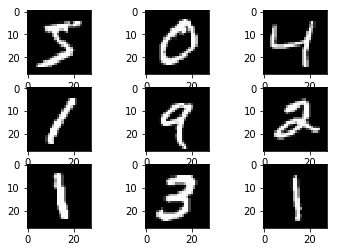

In [0]:
# Plot of images as baseline for comparison
from keras.datasets import mnist
from matplotlib import pyplot
# load data
(X_train, y_train), (X_test, y_test) = mnist.load_data()
# create a grid of 3x3 images
for i in range(0, 9):
  pyplot.subplot(330 + 1 + i)
  pyplot.imshow(X_train[i], cmap=pyplot.get_cmap( 'gray' ))
# show the plot
pyplot.show()

## Feature Standardization
It is also possible to standardize pixel values across the entire dataset. This is called feature standardization and mirrors the type of standardization often performed for each column in a tabular dataset. This is di↵erent to sample standardization described in the previous section as pixel values are standardized across all samples (all images in the dataset). In this case each image is considered a feature. 

In [0]:
# load data
(X_train, y_train), (X_test, y_test) = mnist.load_data()
# reshape to be [samples][pixels][width][height]
X_train = X_train.reshape(X_train.shape[0], 1, 28, 28)
X_test = X_test.reshape(X_test.shape[0], 1, 28, 28)
# convert from int to float
X_train = X_train.astype( 'float32' )
X_test = X_test.astype( 'float32' )

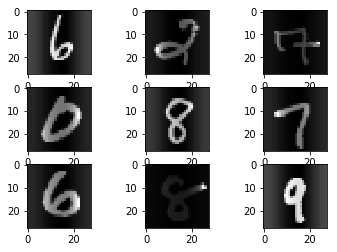

In [0]:
# Standardize images across the dataset, mean=0, stdev=1
from keras.preprocessing.image import ImageDataGenerator
datagen = ImageDataGenerator(featurewise_center=True, featurewise_std_normalization=True)
# fit parameters from data
datagen.fit(X_train)
# configure batch size and retrieve one batch of images
for X_batch, y_batch in datagen.flow(X_train, y_train, batch_size=9):
  # create a grid of 3x3 images
  for i in range(0, 9):
    pyplot.subplot(330 + 1 + i)
    pyplot.imshow(X_batch[i].reshape(28, 28), cmap=pyplot.get_cmap( 'gray' ))
  # show the plot
  pyplot.show()
  break

# ZCA Whitening

A whitening transform of an image is a linear algebra operation that reduces the redundancy in the matrix of pixel images. Less redundancy in the image is intended to better highlight the structures and features in the image to the learning algorithm. Typically, image whitening is performed using the Principal Component Analysis (PCA) technique. More recently, an alternative called ZCA  shows better results and results in transformed images that keeps all of the original dimensions and unlike PCA, resulting transformed images still look like their originals. You can perform a ZCA whitening transform by setting the zca whitening argument to True.
You can read more about ZCA Whitening [here](http://www.cs.toronto.edu/~kriz/learning-features-2009-TR.pdf)

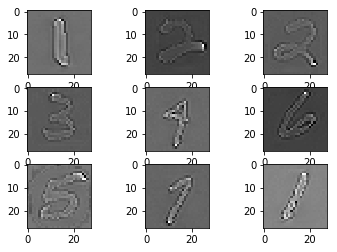

In [0]:
datagen = ImageDataGenerator(zca_whitening=True)
# fit parameters from data
datagen.fit(X_train)
# configure batch size and retrieve one batch of images
for X_batch, y_batch in datagen.flow(X_train, y_train, batch_size=9):
  # create a grid of 3x3 images
  for i in range(0, 9):
    pyplot.subplot(330 + 1 + i)
    pyplot.imshow(X_batch[i].reshape(28, 28), cmap=pyplot.get_cmap( 'gray' ))
  # show the plot
  pyplot.show()
  break

*There are other I mage Agumentation techniques Random rotations, shifts and flips of images. Try Exploring them.*

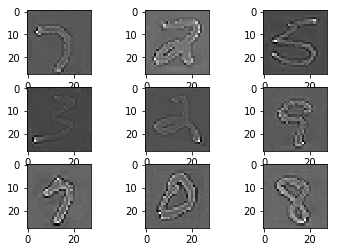

In [0]:
from keras import backend as K
K.set_image_dim_ordering( 'th' )
# define data preparation
datagen = ImageDataGenerator(zca_whitening=True)
# fit parameters from data
datagen.fit(X_train)
# configure batch size and retrieve one batch of images
os.makedirs( 'ZCA-images' )
for X_batch, y_batch in datagen.flow(X_train, y_train, batch_size=9, save_to_dir= 'ZCA-images' ,save_prefix= 'aug' , save_format= 'png' ):
  # create a grid of 3x3 images
  for i in range(0, 9):
    pyplot.subplot(330 + 1 + i)
    pyplot.imshow(X_batch[i].reshape(28, 28), cmap=pyplot.get_cmap( 'gray' ))
  # show the plot
  pyplot.show()
  break

*you can see the same general structure in the images and how the outline of each digit has been highlighted.*

**These images will be saved in the current working directory under the folder  /ZCA-images**

**You can use these images to train your model or create test set out of it.**

----

# Conclusion

In this Data Tale,

We discussed how to visualise high-dimensional data using different Dimensionality Techniques.

We saw different approaches for Supervised Machine Learning classification. 

Convolutional Neural Networks acheived best accuracy of 99.16%  which was remarkable, CNN is a very robust model there is  quite a complex Mathematics Behind it, But remember it is not Magic.

Even Simple Linear Machine Learning Classifier gave us better results. The results obtained with LinearSVC and Randon Forest were less good, but this could probably be improved by using better parameters.

Thats all from our side, do explore how to improve models performance using Image Agumentation. 

*See you on Next Data Tale*